In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/content/1776250375-P2-Healthcare Analytics for Doctor Visits.csv')

In [4]:
df.head()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [5]:
df.tail()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
5185,5186,0,female,0.22,0.55,0,0,0,no,no,no,no,no
5186,5187,0,male,0.27,1.30,0,0,1,no,no,no,no,no
5187,5188,0,female,0.37,0.25,1,0,1,no,no,yes,no,no
5188,5189,0,female,0.52,0.65,0,0,0,no,no,no,no,no
5189,5190,0,male,0.72,0.25,0,0,0,no,no,yes,no,no


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [7]:
df.describe()

,Unnamed: 0,visits,age,income,illness,reduced,health
count,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000
mean,2595.500000,0.301734,0.406385,0.583160,1.431985,0.861850,1.217534
std,1498.368279,0.798134,0.204782,0.368907,1.384152,2.887628,2.124266
min,1.000000,0.000000,0.190000,0.000000,0.000000,0.000000,0.000000
25%,1298.250000,0.000000,0.220000,0.250000,0.000000,0.000000,0.000000
50%,2595.500000,0.000000,0.320000,0.550000,1.000000,0.000000,0.000000
75%,3892.750000,0.000000,0.620000,0.900000,2.000000,0.000000,2.000000
max,5190.000000,9.000000,0.720000,1.500000,5.000000,14.000000,12.000000


In [8]:
df.isnull().sum()

,0
Unnamed: 0,0
visits,0
gender,0
age,0
income,0
illness,0
reduced,0
health,0
private,0
freepoor,0


### Univariate Analysis: Analyzing Key Individual Variables
We will visualize the distribution of three important variables:
1. **Doctor Visits** (Discrete Numerical)
2. **Age** (Continuous Numerical)
3. **Gender** (Categorical)

/tmp/ipykernel_961/1291139947.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0], data=df, x='visits', palette='viridis')


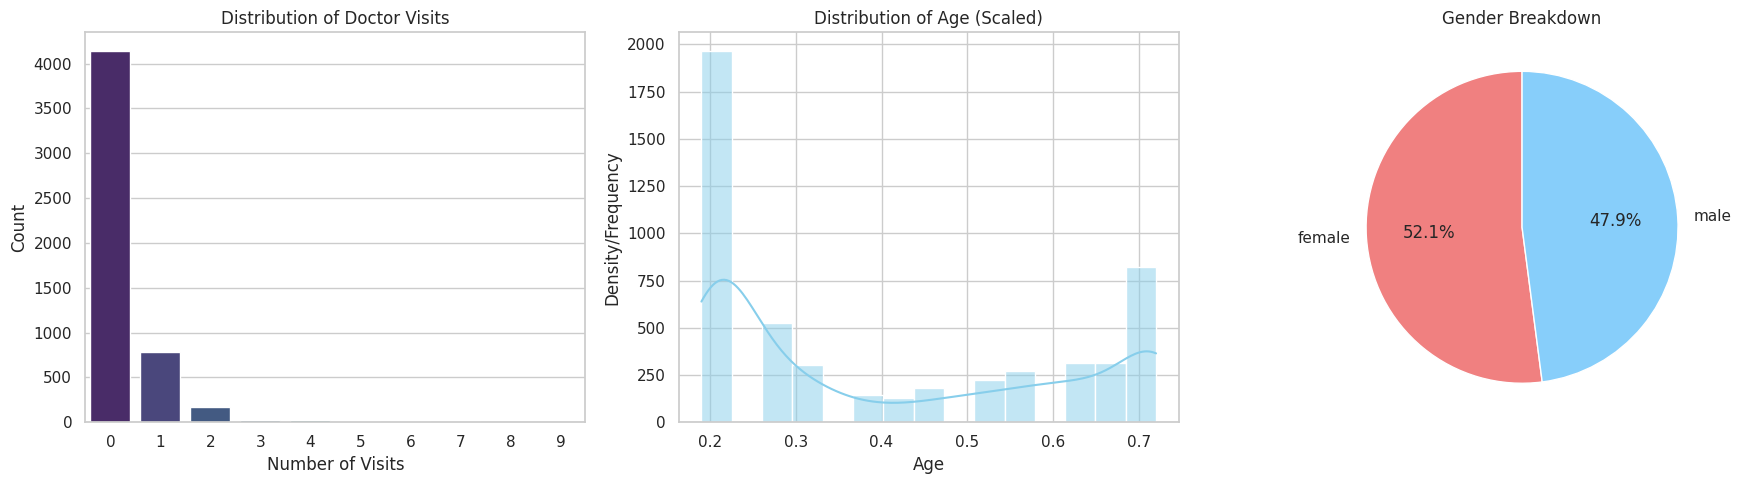

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style of the plots
sns.set_theme(style="whitegrid")

# Create a figure with 3 subplots side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Distribution of Visits (Count Plot)
sns.countplot(ax=axes[0], data=df, x='visits', palette='viridis')
axes[0].set_title('Distribution of Doctor Visits')
axes[0].set_xlabel('Number of Visits')
axes[0].set_ylabel('Count')

# Plot 2: Distribution of Age (Histogram with KDE)
sns.histplot(ax=axes[1], data=df, x='age', kde=True, color='skyblue', bins=15)
axes[1].set_title('Distribution of Age (Scaled)')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Density/Frequency')

# Plot 3: Distribution of Gender (Pie Chart)
gender_counts = df['gender'].value_counts()
axes[2].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', colors=['lightcoral', 'lightskyblue'], startangle=90)
axes[2].set_title('Gender Breakdown')

plt.tight_layout()
plt.show()

,gender,count,mean,median
0,female,2702,0.361954,0.0
1,male,2488,0.236334,0.0


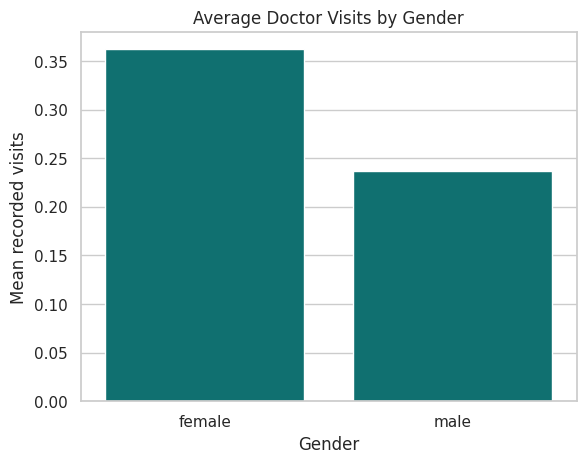

In [12]:
gender_analysis = (
    df.groupby("gender")["visits"]
    .agg(["count","mean","median"])
    .reset_index()
)

display(gender_analysis)

sns.barplot(
    data=gender_analysis,
    x="gender",
    y="mean",
    color='teal'
)
plt.title("Average Doctor Visits by Gender")
plt.xlabel("Gender")
plt.ylabel("Mean recorded visits")
plt.show()



,illness,count,mean,median
0,0,1554,0.078507,0.0
1,1,1638,0.295482,0.0
2,2,946,0.403805,0.0
3,3,542,0.420664,0.0
4,4,274,0.576642,0.0
5,5,236,0.813559,0.0


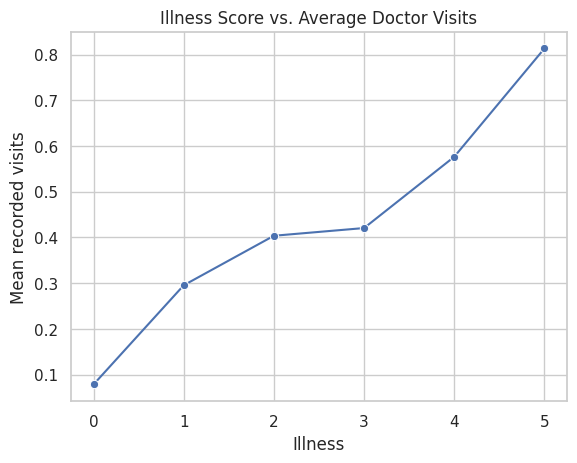

In [13]:
illness_analysis = (
    df.groupby("illness")["visits"]
    .agg(["count","mean","median"])
    .reset_index()
)

display(illness_analysis)

sns.lineplot(
    data=illness_analysis,
    x="illness",
    y="mean",
    marker="o"

)
plt.title("Illness Score vs. Average Doctor Visits")
plt.xlabel("Illness")
plt.ylabel("Mean recorded visits")
plt.show()


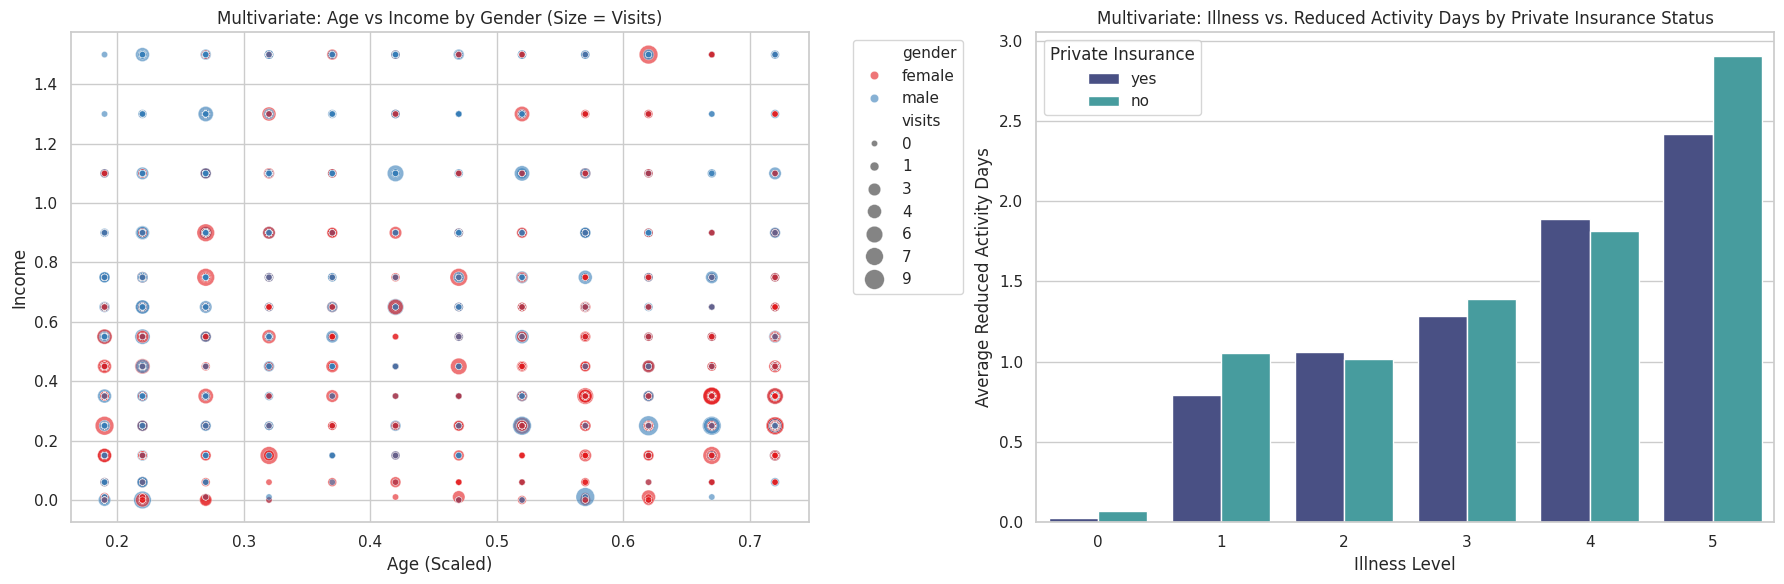

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# Create a figure with 2 distinct multivariate subplots
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Age vs Income, colored by Gender, with size representing Doctor Visits
sns.scatterplot(
    ax=axes[0],
    data=df,
    x="age",
    y="income",
    hue="gender",
    size="visits",
    sizes=(20, 200),
    alpha=0.6,
    palette="Set1"
)
axes[0].set_title("Multivariate: Age vs Income by Gender (Size = Visits)")
axes[0].set_xlabel("Age (Scaled)")
axes[0].set_ylabel("Income")
axes[0].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Plot 2: Interaction of Illness, Reduced Activity Days, and average Doctor Visits by Private Insurance
# Using a bar plot with hue to show three variables together
sns.barplot(
    ax=axes[1],
    data=df,
    x="illness",
    y="reduced",
    hue="private",
    palette="mako",
    errorbar=None
)
axes[1].set_title("Multivariate: Illness vs. Reduced Activity Days by Private Insurance Status")
axes[1].set_xlabel("Illness Level")
axes[1].set_ylabel("Average Reduced Activity Days")
axes[1].legend(title="Private Insurance", loc='upper left')

plt.tight_layout()
plt.show()